**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import shutil

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [5]:
job_name = "net_v8_0per"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v8"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "", 
    "ocsvm_nu": 0.05,                       
    "ocsvm_gamma": "scale", 
    "min_flood_area": 0.0,
    "moco_attn": False,                 
    
    "simple_proj": False,                                                           
    "hidden_channels_dim": 128,
    "pool_grid": 4,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,

    "do_encoder": True,                        # latente autoencoder + pooling di moco
    "do_pre_proj": True,                       # dopo conv + pooling, prima del proiettore
    "do_proj_raw": True,                       # dopo il proiettore, prima della normalizzazione
    "do_post_proj": True,                      # dopo la normalizzazione (come contrastive_loss)
    
    "pca_encoder": None,
    "pca_pre_proj": None,         
    "pca_proj_raw": None,
    "pca_post_proj": None,

    "whitening": "lw",                         # "pca" | "ledoitwolf"
    "fit_on_train": True,                      # True: fit su tutte le serie di train di moco
    "max_fit_series": 0,                        # 0 = tutte; altrimenti campione casuale (ocsvm lento con molte serie)
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "600Gi"}
    }
]

**BUILD ENVIRONMENT**

In [6]:
ocsvm_func = project.new_function(
    name=f'ocsvm_all3',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly_punti:ad_ocsvm3",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [ ]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-11-02 09:22:26,124 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 50db1b5babe8476fb329e0fe6c0a8396 to finish...


2026-11-02 09:22:31,130 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 50db1b5babe8476fb329e0fe6c0a8396 to finish...
2026-11-02 09:22:36,247 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 50db1b5babe8476fb329e0fe6c0a8396 to finish...
2026-11-02 09:22:41,255 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 50db1b5babe8476fb329e0fe6c0a8396 to finish...
2026-11-02 09:22:46,263 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 50db1b5babe8476fb329e0fe6c0a8396 to finish...
2026-11-02 09:22:51,272 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 50db1b5babe8476fb329e0fe6c0a8396 to finish...
2026-11-02 09:22:56,281 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 50db1b5babe8476fb329e0fe6c0a8396 to finish...
2026-11-02 09:23:01,396 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 50db1b5babe8476fb329e0fe6c0a8396 to finish...
2026-11-02 09

In [ ]:
from IPython.display import display

RESULTS_DIR = f"/tmp/anomaly_results_ocsvm_{job_name}"           # una cartella per job
shutil.rmtree(RESULTS_DIR, ignore_errors=True)

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download(f"{RESULTS_DIR}.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)

with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
punti = list(summary["punti"].keys())                              # solo i punti calcolati in questa run
print(f"job: {job_name} | moco: {summary['moco_version']} | punti: {', '.join(punti)}", "\n")

dati = {}          # punto -> (results, df), per i grafici
righe = []

for punto in punti:
    with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{RESULTS_DIR}/{punto}/scores.csv")
    dati[punto] = (results, df)

    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    print(f"===== {punto} =====")
    print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}")
    print(f"whitening: {results.get('whitening', 'pca')} | componenti: {results['n_componenti']} | shrinkage: {results.get('shrinkage')}")
    print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']:.3f}")
    print(f"min_flood_area = {results['min_flood_area']:.3f}")
    print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
    print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}")
    print(f"AUROC: {results['auroc']:.3f}")

    display(pd.DataFrame(results["rules"]).T)                      # regole del punto

    righe.append({"punto": punto, "componenti": results["n_componenti"],
                  "shrinkage": results.get("shrinkage"), "AUROC": results["auroc"]})

# confronto tra i punti
print("===== CONFRONTO =====")
pd.DataFrame(righe).set_index("punto").round(3)

job: net_v8_0per_lw | moco: net_v8 | punti: encoder, pre_proj, proj_raw, post_proj 

===== encoder =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 512 | shrinkage: 0.0024228534744755678
nu: 0.05 | gamma: scale | dim: 512 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 26.7015 ± 17.4207
score anomale: 1.7694 ± 14.8177
AUROC: 0.855


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-4.092149,978.0,107.0,1424.0,2295.0,0.044546,0.592839,0.407161,0.901382,0.560941
FA 10%,1.884100,1338.0,196.0,1064.0,2206.0,0.081599,0.442964,0.557036,0.872229,0.679878
FA 15%,6.747321,1556.0,325.0,846.0,2077.0,0.135304,0.352206,0.647794,0.827220,0.726594
FA 20%,10.229344,1711.0,451.0,691.0,1951.0,0.187760,0.287677,0.712323,0.791397,0.749781
FA 25%,13.568295,1855.0,571.0,547.0,1831.0,0.237719,0.227727,0.772273,0.764633,0.768434
FA 30%,16.678342,1954.0,710.0,448.0,1692.0,0.295587,0.186511,0.813489,0.733483,0.771417


===== pre_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 4096 | shrinkage: 0.02204915092568871
nu: 0.05 | gamma: scale | dim: 4096 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 16.7162 ± 17.3402
score anomale: -0.5193 ± 15.5669
AUROC: 0.767


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-18.138110,352.0,85.0,2050.0,2317.0,0.035387,0.853455,0.146545,0.805492,0.247975
FA 10%,-10.810833,719.0,182.0,1683.0,2220.0,0.075770,0.700666,0.299334,0.798002,0.435362
FA 15%,-4.563495,1063.0,305.0,1339.0,2097.0,0.126978,0.557452,0.442548,0.777047,0.563926
FA 20%,-0.472271,1271.0,418.0,1131.0,1984.0,0.174022,0.470858,0.529142,0.752516,0.621364
FA 25%,3.730538,1467.0,567.0,935.0,1835.0,0.236053,0.389259,0.610741,0.721239,0.661407
FA 30%,6.851962,1596.0,676.0,806.0,1726.0,0.281432,0.335554,0.664446,0.702465,0.682927


===== proj_raw =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.02245711823128529
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.048
min_flood_area = 0.000
score normali: 9.7744 ± 5.2751
score anomale: 5.9189 ± 4.9735
AUROC: 0.708


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-1.521778,185.0,81.0,2217.0,2321.0,0.033722,0.922981,0.077019,0.695489,0.138681
FA 10%,1.035295,483.0,212.0,1919.0,2190.0,0.088260,0.798918,0.201082,0.694964,0.311915
FA 15%,3.340583,781.0,344.0,1621.0,2058.0,0.143214,0.674854,0.325146,0.694222,0.442869
FA 20%,4.801015,1020.0,442.0,1382.0,1960.0,0.184013,0.575354,0.424646,0.697674,0.527950
FA 25%,6.005807,1201.0,531.0,1201.0,1871.0,0.221066,0.500000,0.500000,0.693418,0.581035
FA 30%,7.098268,1401.0,637.0,1001.0,1765.0,0.265196,0.416736,0.583264,0.687439,0.631081


===== post_proj =====
n_fit: 19893 | n_thr: 2572 | n_normali: 2402 | n_anomale: 2402
whitening: lw | componenti: 256 | shrinkage: 0.0035041000737800355
nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.050
min_flood_area = 0.000
score normali: 3.3412 ± 13.4280
score anomale: 3.1125 ± 13.8896
AUROC: 0.503


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-17.911156,148.0,130.0,2254.0,2272.0,0.054122,0.938385,0.061615,0.532374,0.110448
FA 10%,-13.093100,278.0,247.0,2124.0,2155.0,0.102831,0.884263,0.115737,0.529524,0.189956
FA 15%,-9.965361,391.0,359.0,2011.0,2043.0,0.149459,0.837219,0.162781,0.521333,0.248096
FA 20%,-7.042645,539.0,520.0,1863.0,1882.0,0.216486,0.775604,0.224396,0.508971,0.311471
FA 25%,-4.607084,683.0,661.0,1719.0,1741.0,0.275187,0.715654,0.284346,0.508185,0.364656
FA 30%,-2.666707,802.0,788.0,1600.0,1614.0,0.328060,0.666112,0.333888,0.504403,0.401804


===== CONFRONTO =====


,componenti,shrinkage,AUROC
punto,,,
encoder,512,0.002,0.855
pre_proj,4096,0.022,0.767
proj_raw,256,0.022,0.708
post_proj,256,0.004,0.503


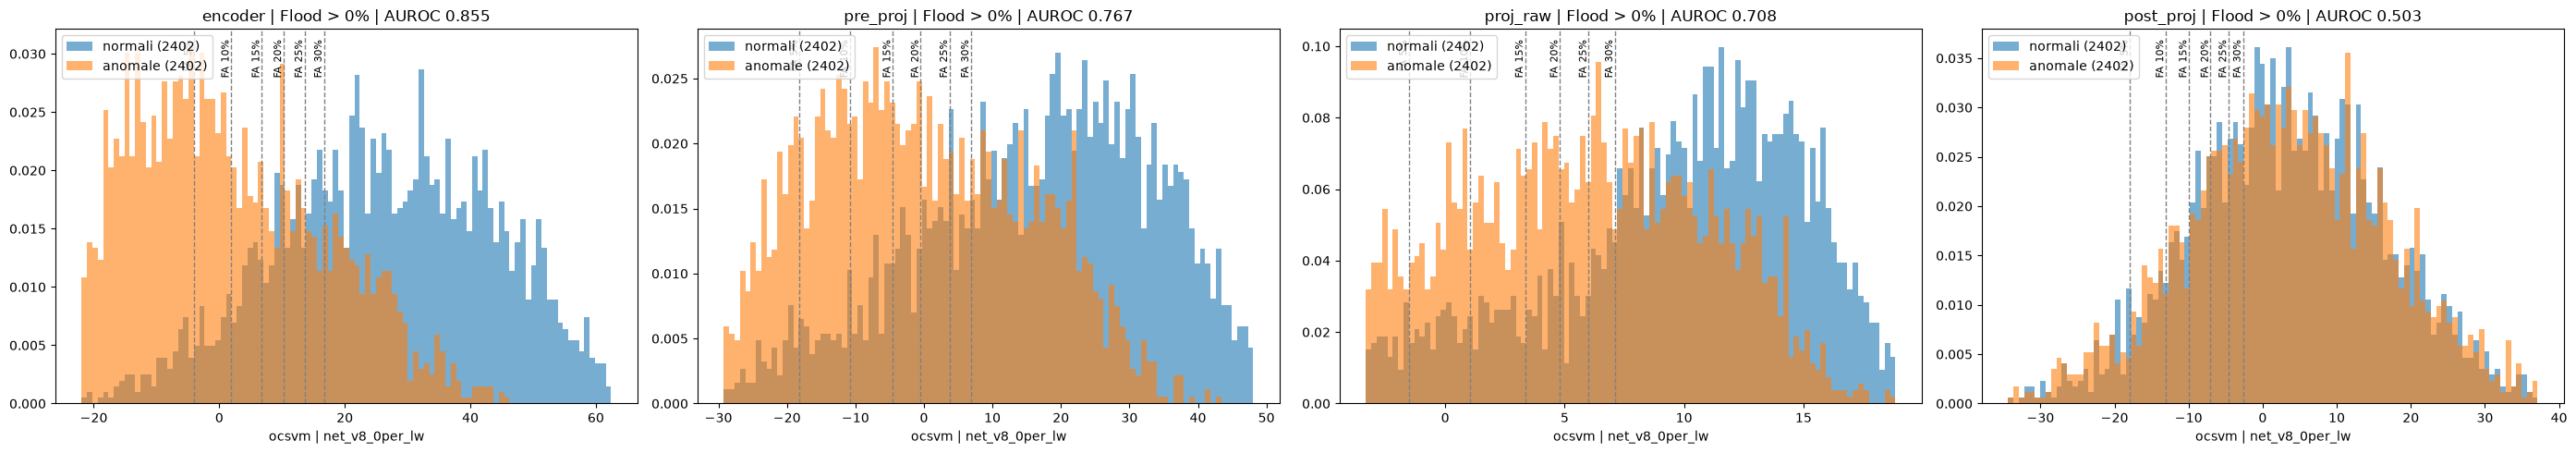

In [ ]:
fig, axes = plt.subplots(1, len(punti), figsize=(7 * len(punti), 5), squeeze=False)

for ax, punto in zip(axes[0], punti):
    results, df = dati[punto]
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)

    ax.set_xlabel(f"ocsvm | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"{punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}")

plt.tight_layout()
plt.show()

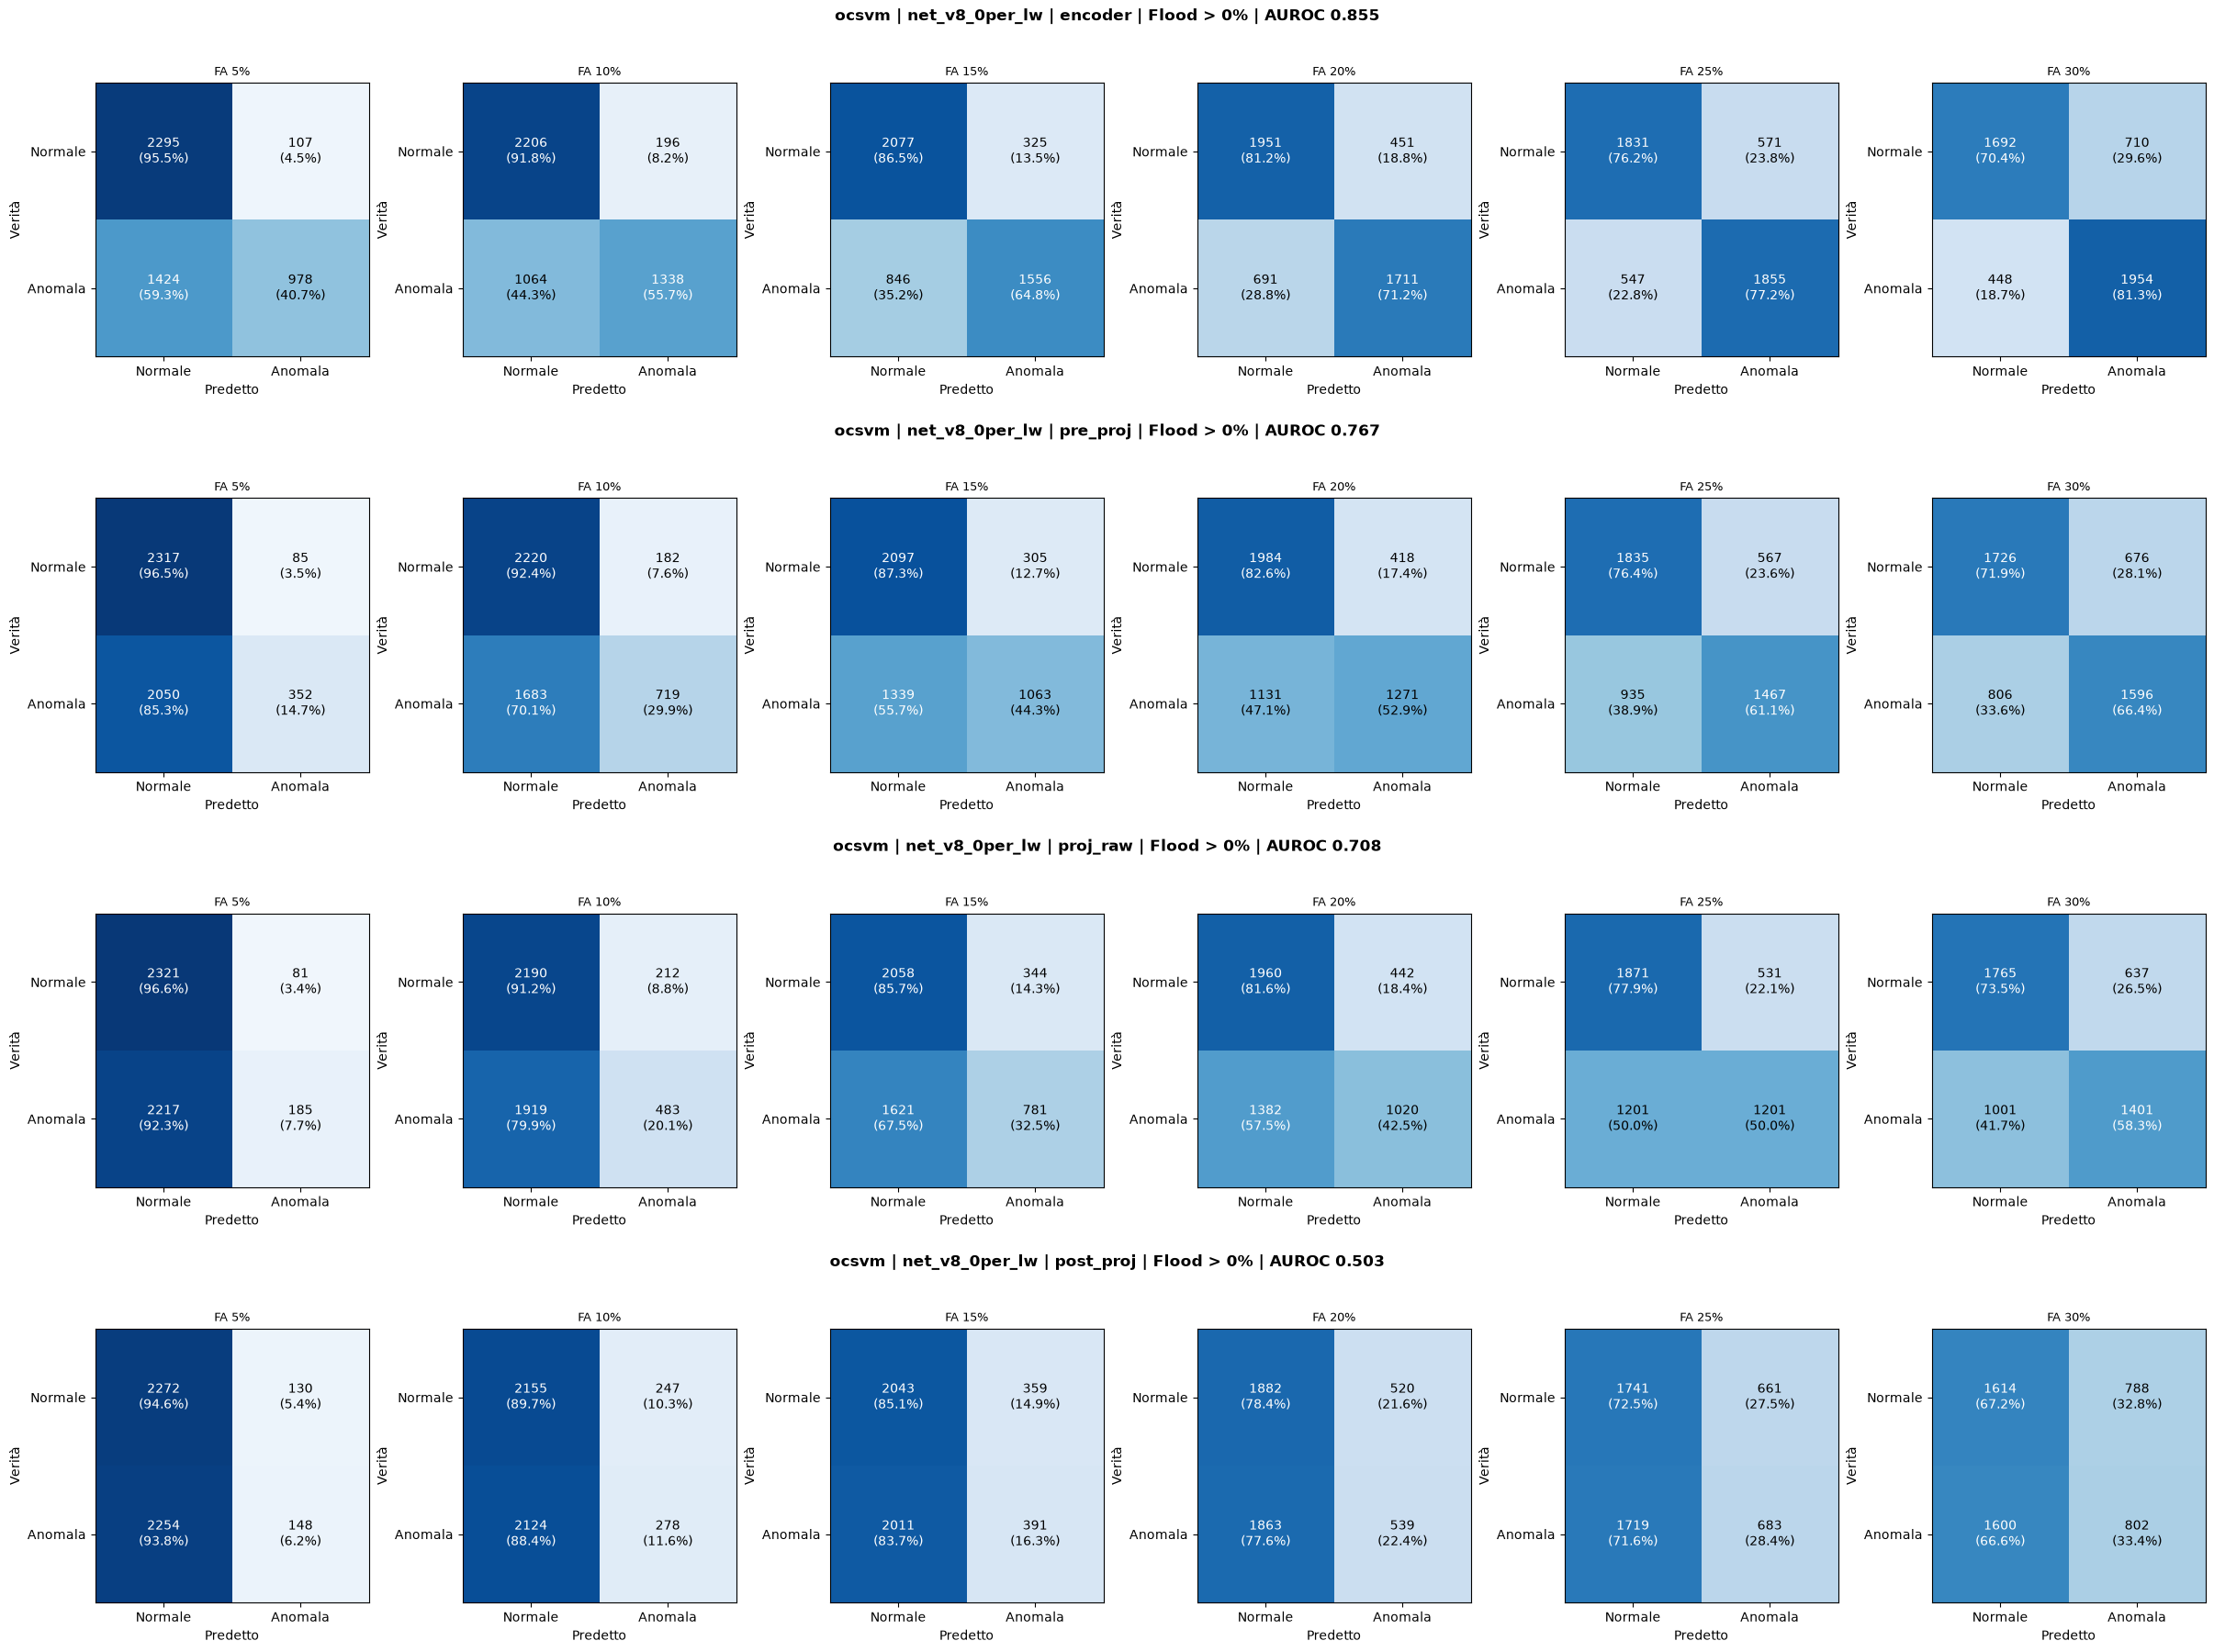

In [ ]:
n_cols = max(len(dati[p][0]["rules"]) for p in punti)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * len(punti)), layout="constrained")
subfigs = np.atleast_1d(fig.subfigures(len(punti), 1))

for sfig, punto in zip(subfigs, punti):
    results, _ = dati[punto]
    rules = results["rules"]
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"ocsvm | {job_name} | {punto} | Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}",
                  fontsize=12, fontweight="bold")

plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf

punto = "pre_proj"

# verifica dei risultati caricati
with open(f"{RESULTS_DIR}/summary.json") as f:
    summary = json.load(f)
with open(f"{RESULTS_DIR}/{punto}/anomaly_results.json") as f:
    info = json.load(f)

print(f"cartella:      {RESULTS_DIR}")
print(f"job:           {summary['job_name']} | moco: {summary['moco_version']} | dataset anomalie: {summary['dataset_anomalies']}")
print(f"fit_on_train:  {summary.get('fit_on_train')} | punti nella run: {', '.join(summary['punti'].keys())}")
print(f"punto:         {info['feature_point']} | min_flood_area: {info['min_flood_area']}")
print(f"serie:         fit {info['n_fit']} | thr {info['n_thr']} | normali {info['n_normali']} | anomale {info['n_anomale']}")
print(f"AUROC nel job: {info['auroc']:.3f} ({info['metodo']}, whitening {info.get('whitening', 'pca')}, {info['n_componenti']} componenti)", "\n")

E = np.load(f"{RESULTS_DIR}/{punto}/embeddings.npz")
cat = lambda g: np.concatenate([E[f"{g}_q"], E[f"{g}_k"]], axis=1).astype(np.float64)

w = {g: cat(g) for g in ("fit", "thr", "normal", "anom")}
print("forme:", {g: v.shape for g, v in w.items()}, "\n")

scaler = StandardScaler().fit(w["fit"])
w = {g: scaler.transform(v) for g, v in w.items()}

pca = PCA(whiten=True).fit(w["fit"])                     # una sola PCA con tutte le componenti
z = {g: pca.transform(v) for g, v in w.items()}


rng = np.random.default_rng(0)
ia = rng.permutation(len(z["anom"]));   a_val, a_test = ia[: len(ia) // 2], ia[len(ia) // 2:]
i_n = rng.permutation(len(z["normal"])); n_val, n_test = i_n[: len(i_n) // 2], i_n[len(i_n) // 2:]

def auroc(md, n_idx, a_idx):
    y = np.r_[np.zeros(len(n_idx)), np.ones(len(a_idx))]
    return roc_auc_score(y, np.r_[md["normal"][n_idx], md["anom"][a_idx]])

righe = []
for k in (32, 64, 128, 256, 512, 768, 1024, 1536, 2048, 3072, 4096):
    if k > z["fit"].shape[1]:
        break
    md = {g: (v[:, :k] ** 2).sum(1) for g, v in z.items()}         
    righe.append({
        "k": k,
        "rapporto soglia/fit": md["thr"].mean() / md["fit"].mean(),  
        "AUROC validazione": auroc(md, n_val, a_val),                
    })


lw = LedoitWolf().fit(w["fit"])
md = {g: lw.mahalanobis(v) for g, v in w.items()}                   
righe.append({
    "k": f"LW ({w['fit'].shape[1]})",
    "rapporto soglia/fit": md["thr"].mean() / md["fit"].mean(),
    "AUROC validazione": auroc(md, n_val, a_val),
})
print(f"Ledoit-Wolf shrinkage: {lw.shrinkage_:.3f}")

scelta = pd.DataFrame(righe).set_index("k")
print(scelta.round(3))

cartella:      /tmp/anomaly_results_ocsvm_net_v8_0per_lw
job:           net_v8_0per_lw | moco: net_v8 | dataset anomalie: Floods_Anomalies_v3_crop_norm
fit_on_train:  True | punti nella run: encoder, pre_proj, proj_raw, post_proj
punto:         pre_proj | min_flood_area: 0.0
serie:         fit 19893 | thr 2572 | normali 2402 | anomale 2402
AUROC nel job: 0.767 (ocsvm, whitening lw, 4096 componenti) 

forme: {'fit': (19893, 4096), 'thr': (2572, 4096), 'normal': (2402, 4096), 'anom': (2402, 4096)} 

Ledoit-Wolf shrinkage: 0.022
           rapporto soglia/fit  AUROC validazione
k                                                
32                       1.089              0.656
64                       1.062              0.686
128                      1.027              0.702
256                      0.989              0.723
512                      0.947              0.744
768                      0.930              0.752
1024                     0.924              0.756
1536              